In [75]:
%pip install pandas numpy scikit-learn lightgbm xgboost catboost optuna shap fairlearn mlflow matplotlib seaborn pyarrow

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
pd.options.display.max_rows=900 # afficher beaucoup de ligne
pd.options.display.max_columns=200 # afficher

In [5]:
from pathlib import Path

SEED = 42
DATA = Path("data")

In [6]:
# data train
hc = pd.read_csv(DATA / "application_train.csv")
# data test
#ch = pd.read_csv(DATA / "application_test.csv")
print(hc.shape)
hc.head()




(307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [7]:
target = "TARGET"
hc[target].value_counts()



TARGET
0    282686
1     24825
Name: count, dtype: int64

In [8]:
hc["CODE_GENDER"].value_counts()
hc.groupby("CODE_GENDER")[target].mean() # taux de defauts selon le sexe

CODE_GENDER
F      0.069993
M      0.101419
XNA    0.000000
Name: TARGET, dtype: float64

In [9]:
# pourcentage de des valeurs du target
print(hc[target].value_counts(normalize=True))
#print(f"Ratio bons/défauts : {counts[0] / counts[1]:.1f} pour 1")

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


In [10]:
# valeurs manquantes
#missing_values = hc.isna().mean() 
missing_values = hc.isnull().mean()
missing_values
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
#print(missing_values)
missing_values.head(20)

COMMONAREA_MEDI             0.698723
COMMONAREA_AVG              0.698723
COMMONAREA_MODE             0.698723
NONLIVINGAPARTMENTS_MEDI    0.694330
NONLIVINGAPARTMENTS_MODE    0.694330
NONLIVINGAPARTMENTS_AVG     0.694330
FONDKAPREMONT_MODE          0.683862
LIVINGAPARTMENTS_MODE       0.683550
LIVINGAPARTMENTS_MEDI       0.683550
LIVINGAPARTMENTS_AVG        0.683550
FLOORSMIN_MODE              0.678486
FLOORSMIN_MEDI              0.678486
FLOORSMIN_AVG               0.678486
YEARS_BUILD_MODE            0.664978
YEARS_BUILD_MEDI            0.664978
YEARS_BUILD_AVG             0.664978
OWN_CAR_AGE                 0.659908
LANDAREA_AVG                0.593767
LANDAREA_MEDI               0.593767
LANDAREA_MODE               0.593767
dtype: float64

In [11]:
# Valeurs manquantes peuvent donner des informations 
rows = []
for col in missing_values.head(15).index:
        is_na = hc[col].isna()
        rows.append({
        "colonne": col,
        "% manquant": is_na.mean(),
        "défaut si manquant": hc.loc[is_na, target].mean(),
        "défaut si présent": hc.loc[~is_na, target].mean(),
    })

pd.DataFrame(rows).round(4)

,colonne,% manquant,défaut si manquant,défaut si présent
0,COMMONAREA_MEDI,0.6987,0.0857,0.0691
1,COMMONAREA_AVG,0.6987,0.0857,0.0691
2,COMMONAREA_MODE,0.6987,0.0857,0.0691
3,NONLIVINGAPARTMENTS_MEDI,0.6943,0.0858,0.0691
4,NONLIVINGAPARTMENTS_MODE,0.6943,0.0858,0.0691
5,NONLIVINGAPARTMENTS_AVG,0.6943,0.0858,0.0691
6,FONDKAPREMONT_MODE,0.6839,0.0862,0.0689
7,LIVINGAPARTMENTS_MODE,0.6835,0.0862,0.0689
8,LIVINGAPARTMENTS_MEDI,0.6835,0.0862,0.0689
9,LIVINGAPARTMENTS_AVG,0.6835,0.0862,0.0689


In [12]:
#hc.describe()
#hc.info()
#from sklearn.compose import make_column_selector as selector
#categorical_columns_selector = selector(dtype_include=object)

# variables catégorielles
hc.dtypes.value_counts()
categorical_cols = hc.select_dtypes(include="object").columns.tolist()
hc[categorical_cols].nunique().sort_values(ascending=False)


/var/folders/ws/mjhdb5m154j24bhbln47dgg80000gn/T/ipykernel_82157/3011757728.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = hc.select_dtypes(include="object").columns.tolist()


ORGANIZATION_TYPE             58
OCCUPATION_TYPE               18
NAME_INCOME_TYPE               8
NAME_TYPE_SUITE                7
WEEKDAY_APPR_PROCESS_START     7
WALLSMATERIAL_MODE             7
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
NAME_EDUCATION_TYPE            5
FONDKAPREMONT_MODE             4
CODE_GENDER                    3
HOUSETYPE_MODE                 3
NAME_CONTRACT_TYPE             2
FLAG_OWN_CAR                   2
FLAG_OWN_REALTY                2
EMERGENCYSTATE_MODE            2
dtype: int64

In [13]:
# traitement de nombre de jours de travail
print(hc["DAYS_EMPLOYED"].describe())
anom = hc["DAYS_EMPLOYED"] == 365243 ## 1 si 
print(f"Clients concernés : {anom.sum()} ({anom.mean():.1%})")
print(f"Défaut si anomalie : {hc.loc[anom, target].mean():.2%}")
print(f"Défaut sinon       : {hc.loc[~anom, target].mean():.2%}")
hc["DAYS_EMPLOYED_ANOM"] = anom.astype(int)
hc["DAYS_EMPLOYED"] = hc["DAYS_EMPLOYED"].replace(365243, np.nan)

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64
Clients concernés : 55374 (18.0%)
Défaut si anomalie : 5.40%
Défaut sinon       : 8.66%


In [14]:
# traitement de l'age
hc["AGE_YEARS"] = -hc["DAYS_BIRTH"] / 365
print(hc["AGE_YEARS"].describe())
print(hc["AMT_INCOME_TOTAL"].quantile([0.5, 0.9, 0.99, 0.999, 1.0]))

count    307511.000000
mean         43.936973
std          11.956133
min          20.517808
25%          34.008219
50%          43.150685
75%          53.923288
max          69.120548
Name: AGE_YEARS, dtype: float64
0.500       147150.0
0.900       270000.0
0.990       472500.0
0.999       900000.0
1.000    117000000.0
Name: AMT_INCOME_TOTAL, dtype: float64


In [15]:
print((hc["AMT_INCOME_TOTAL"] > 10_000_000).sum())
print(hc["CODE_GENDER"].value_counts())
print(hc.loc[anom, "NAME_INCOME_TYPE"].value_counts(normalize=True).head())

3
CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64
NAME_INCOME_TYPE
Pensioner     0.999603
Unemployed    0.000397
Name: proportion, dtype: float64


In [16]:
# correlation
corr = hc.select_dtypes(include="number").corr()[target].drop(target)
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
corr.head(15)

EXT_SOURCE_3                  -0.178919
EXT_SOURCE_2                  -0.160472
EXT_SOURCE_1                  -0.155317
AGE_YEARS                     -0.078239
DAYS_BIRTH                     0.078239
DAYS_EMPLOYED                  0.074958
REGION_RATING_CLIENT_W_CITY    0.060893
REGION_RATING_CLIENT           0.058899
DAYS_LAST_PHONE_CHANGE         0.055218
DAYS_ID_PUBLISH                0.051457
REG_CITY_NOT_WORK_CITY         0.050994
DAYS_EMPLOYED_ANOM            -0.045987
FLAG_EMP_PHONE                 0.045982
REG_CITY_NOT_LIVE_CITY         0.044395
FLAG_DOCUMENT_3                0.044346
Name: TARGET, dtype: float64

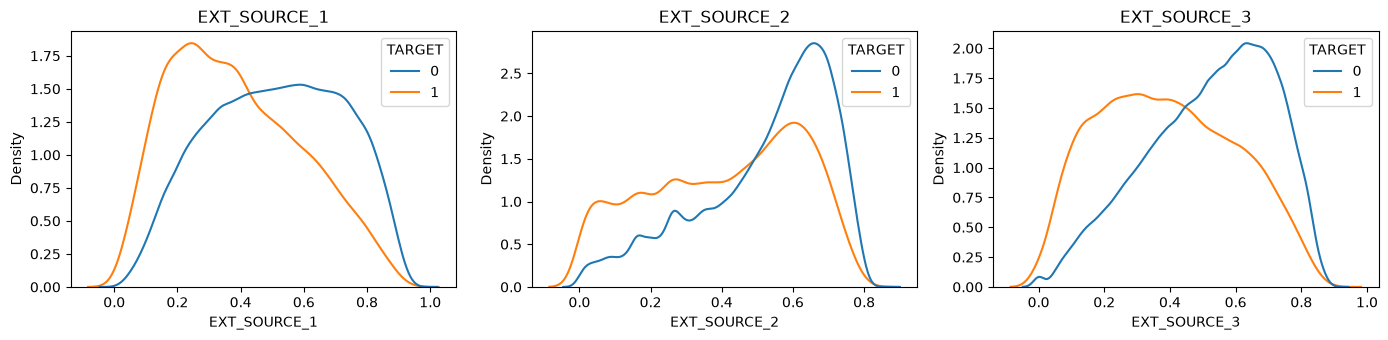

In [17]:
# concentration 
# histograme lissé
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
        sns.kdeplot(data=hc, x=col, hue=target, common_norm=False, ax=ax)
        ax.set_title(col)
plt.tight_layout()
plt.show()

In [18]:
def default_rate(col, min_count=500):
    g = hc.groupby(col, dropna=False)[target].agg(["mean", "count"])
    return g[g["count"] >= min_count].sort_values("mean", ascending=False)

default_rate("NAME_EDUCATION_TYPE")
default_rate("OCCUPATION_TYPE")
default_rate("ORGANIZATION_TYPE").head(10)

,mean,count
ORGANIZATION_TYPE,,
Transport: type 3,0.157540,1187
Restaurant,0.117062,1811
Construction,0.116798,6721
Industry: type 1,0.110683,1039
Industry: type 3,0.106162,3278
Agriculture,0.104727,2454
Trade: type 3,0.103379,3492
Self-employed,0.101739,38412
Industry: type 4,0.101482,877


In [19]:
tables = ["bureau", "bureau_balance", "previous_application",
          "POS_CASH_balance", "installments_payments", "credit_card_balance"]
cols = {}
for t in tables:
    cols[t] = pd.read_csv(DATA / f"{t}.csv", nrows=0).columns.tolist()

keys = ["SK_ID_CURR", "SK_ID_PREV", "SK_ID_BUREAU"]
pd.DataFrame({k: [k in cols[t] for t in tables] for k in keys}, index=tables)

,SK_ID_CURR,SK_ID_PREV,SK_ID_BUREAU
bureau,True,False,True
bureau_balance,False,False,True
previous_application,True,True,False
POS_CASH_balance,True,True,False
installments_payments,True,True,False
credit_card_balance,True,True,False


In [20]:
# import des données de la tables bureau
bureau = pd.read_csv(DATA / "bureau.csv")
print(bureau.shape)
bureau.head()
has_bureau = hc["SK_ID_CURR"].isin(bureau["SK_ID_CURR"])
print(f"Clients avec au moins un crédit au bureau : {has_bureau.mean():.1%}")
print(hc.groupby(has_bureau)[target].agg(["mean", "count"]))
n_credits = bureau.groupby("SK_ID_CURR").size()
print(n_credits.describe())

(1716428, 17)
Clients avec au moins un crédit au bureau : 85.7%
                mean   count
SK_ID_CURR                  
False       0.101249   44020
True        0.077301  263491
count    305811.000000
mean          5.612709
std           4.430354
min           1.000000
25%           2.000000
50%           4.000000
75%           8.000000
max         116.000000
dtype: float64


In [21]:
#  Agrégation et jointure
# créer de nouvelles pour faire comprendre à la machine
# dictionnaire
bureau_num_aggs = {
    "DAYS_CREDIT": ["min", "max"],
    "CREDIT_DAY_OVERDUE": ["max"],
    "AMT_CREDIT_MAX_OVERDUE": ["max"],
    "AMT_CREDIT_SUM": ["sum", "max"],
    "AMT_CREDIT_SUM_DEBT": ["sum", "max"],
    "AMT_CREDIT_SUM_OVERDUE": ["sum"],
    "CNT_CREDIT_PROLONG": ["sum"],
}
bureau_agg = bureau.groupby("SK_ID_CURR").agg(bureau_num_aggs)
bureau_agg.columns = ["BUREAU_" + "_".join(c).upper() for c in bureau_agg.columns]
bureau_agg["BUREAU_N_CREDITS"] = bureau.groupby("SK_ID_CURR").size()
active = bureau[bureau["CREDIT_ACTIVE"] == "Active"]
active_agg = active.groupby("SK_ID_CURR").agg(
    BUREAU_ACTIVE_N=("SK_ID_BUREAU", "count"),
    BUREAU_ACTIVE_DEBT_SUM=("AMT_CREDIT_SUM_DEBT", "sum"),
)
bureau_agg = bureau_agg.join(active_agg, how="left")
bureau_agg[["BUREAU_ACTIVE_N", "BUREAU_ACTIVE_DEBT_SUM"]] = (
    bureau_agg[["BUREAU_ACTIVE_N", "BUREAU_ACTIVE_DEBT_SUM"]].fillna(0)
)
bureau_agg["BUREAU_DEBT_RATIO"] = (
    bureau_agg["BUREAU_AMT_CREDIT_SUM_DEBT_SUM"]
    / bureau_agg["BUREAU_AMT_CREDIT_SUM_SUM"].replace(0, np.nan)
)

# left attribue NaN
# inner supprime si il n'ya pas de cases correspondant
df = hc.copy()
df = df.join(bureau_agg, on="SK_ID_CURR", how="left")
assert len(df) == len(hc), "La jointure a dupliqué des lignes !"
df["HAS_BUREAU"] = df["BUREAU_N_CREDITS"].notna().astype(int)
df["BUREAU_N_CREDITS"] = df["BUREAU_N_CREDITS"].fillna(0)
print(df.shape)
print(df.groupby("HAS_BUREAU")[target].agg(["mean", "count"]))

(307511, 139)
                mean   count
HAS_BUREAU                  
0           0.101249   44020
1           0.077301  263491


In [22]:
# Import de la table bureau_balance
bb = pd.read_csv(DATA / "bureau_balance.csv")
print(bb.shape)

(27299925, 3)


In [23]:
print(bb["STATUS"].value_counts(normalize=True))

STATUS
C    0.499891
0    0.274708
X    0.212839
1    0.008877
5    0.002286
2    0.000858
3    0.000327
4    0.000214
Name: proportion, dtype: float64


In [24]:
bb["IS_LATE"] = bb["STATUS"].isin(["1", "2", "3", "4", "5"]).astype(int)
bb["STATUS_NUM"] = pd.to_numeric(bb["STATUS"], errors="coerce")
bb_agg = bb.groupby("SK_ID_BUREAU").agg(
    BB_MONTHS_COUNT=("MONTHS_BALANCE", "count"),
    BB_LATE_COUNT=("IS_LATE", "sum"),
    BB_LATE_RATE=("IS_LATE", "mean"),
    BB_WORST_STATUS=("STATUS_NUM", "max"),
)

In [25]:
link = bureau.set_index("SK_ID_BUREAU")["SK_ID_CURR"]
bb_agg = bb_agg.join(link, how="inner")
client_bb = bb_agg.groupby("SK_ID_CURR").agg(
    BB_LATE_COUNT_SUM=("BB_LATE_COUNT", "sum"),
    BB_LATE_RATE_MEAN=("BB_LATE_RATE", "mean"),
    BB_LATE_RATE_MAX=("BB_LATE_RATE", "max"),
    BB_WORST_STATUS_MAX=("BB_WORST_STATUS", "max"),
    BB_MONTHS_TOTAL=("BB_MONTHS_COUNT", "sum"),
)
df = df.drop(columns=client_bb.columns, errors="ignore").join(client_bb, on="SK_ID_CURR", how="left")
assert len(df) == len(hc), "La jointure a dupliqué des lignes !"
print(df.shape)
print(df["BB_WORST_STATUS_MAX"].value_counts(dropna=False).sort_index())

(307511, 144)
BB_WORST_STATUS_MAX
0.0     58804
1.0     24686
2.0      2961
3.0       794
4.0       405
5.0      2206
NaN    217655
Name: count, dtype: int64


In [26]:
df.groupby("BB_WORST_STATUS_MAX", dropna=False)[target].agg(["mean", "count"])

,mean,count
BB_WORST_STATUS_MAX,,
0.0,0.072002,58804
1.0,0.100583,24686
2.0,0.087470,2961
3.0,0.085642,794
4.0,0.096296,405
5.0,0.110154,2206
NaN,0.080398,217655


In [27]:
df.groupby(["HAS_BUREAU", df["BB_WORST_STATUS_MAX"].isna()])[target].agg(["mean", "count"])

mean   count
HAS_BUREAU BB_WORST_STATUS_MAX                  
0          True                 0.101249   44020
1          False                0.081530   89856
           True                 0.075112  173635

In [28]:
df["HAS_BB_STATUS"] = df["BB_WORST_STATUS_MAX"].notna().astype(int)
df.groupby(["HAS_BUREAU", "HAS_BB_STATUS"])[target].agg(["mean", "count"])

mean   count
HAS_BUREAU HAS_BB_STATUS                  
0          0              0.101249   44020
1          0              0.075112  173635
           1              0.081530   89856

In [29]:
def summarize(t, prefix, stats=("mean", "max")):
    num = t.select_dtypes(include="number").drop(columns=["SK_ID_PREV"], errors="ignore")
    agg = num.groupby("SK_ID_CURR").agg(list(stats))
    agg.columns = [f"{prefix}_{c}_{s}".upper() for c, s in agg.columns]
    agg[f"{prefix}_N_ROWS".upper()] = num.groupby("SK_ID_CURR").size()
    return agg

def add_features(d, feats):
    d = d.drop(columns=feats.columns, errors="ignore")
    return d.join(feats, on="SK_ID_CURR", how="left")




In [30]:
del bb, bb_agg

In [31]:
prev = pd.read_csv(DATA / "previous_application.csv")
for c in ["DAYS_FIRST_DRAWING", "DAYS_FIRST_DUE", "DAYS_LAST_DUE_1ST_VERSION",
          "DAYS_LAST_DUE", "DAYS_TERMINATION"]:
    prev[c] = prev[c].replace(365243, np.nan)

prev["PREV_APPROVED"] = (prev["NAME_CONTRACT_STATUS"] == "Approved").astype(int)
prev["PREV_REFUSED"] = (prev["NAME_CONTRACT_STATUS"] == "Refused").astype(int)
prev["PREV_CREDIT_RATIO"] = prev["AMT_CREDIT"] / prev["AMT_APPLICATION"].replace(0, np.nan)
prev_agg = summarize(prev, "PREV")
del prev

In [32]:
pos = pd.read_csv(DATA / "POS_CASH_balance.csv")
pos_agg = summarize(pos, "POS")
del pos

In [33]:
inst = pd.read_csv(DATA / "installments_payments.csv")
inst["DAYS_LATE"] = (inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]).clip(lower=0)
inst["IS_LATE"] = (inst["DAYS_LATE"] > 0).astype(int)
inst["PAY_RATIO"] = inst["AMT_PAYMENT"] / inst["AMT_INSTALMENT"].replace(0, np.nan)
inst_agg = summarize(inst, "INST")
del inst

In [34]:
cc = pd.read_csv(DATA / "credit_card_balance.csv")
cc_agg = summarize(cc, "CC")
del cc

In [35]:
for feats in [prev_agg, pos_agg, inst_agg, cc_agg]:
    df = add_features(df, feats)

In [36]:
assert len(df) == len(hc), "La jointure a dupliqué des lignes !"
print(df.shape)

(307511, 261)


In [37]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,...,PREV_RATE_INTEREST_PRIMARY_MEAN,PREV_RATE_INTEREST_PRIMARY_MAX,PREV_RATE_INTEREST_PRIVILEGED_MEAN,PREV_RATE_INTEREST_PRIVILEGED_MAX,PREV_DAYS_DECISION_MEAN,PREV_DAYS_DECISION_MAX,PREV_SELLERPLACE_AREA_MEAN,PREV_SELLERPLACE_AREA_MAX,PREV_CNT_PAYMENT_MEAN,PREV_CNT_PAYMENT_MAX,PREV_DAYS_FIRST_DRAWING_MEAN,PREV_DAYS_FIRST_DRAWING_MAX,PREV_DAYS_FIRST_DUE_MEAN,PREV_DAYS_FIRST_DUE_MAX,PREV_DAYS_LAST_DUE_1ST_VERSION_MEAN,PREV_DAYS_LAST_DUE_1ST_VERSION_MAX,PREV_DAYS_LAST_DUE_MEAN,PREV_DAYS_LAST_DUE_MAX,PREV_DAYS_TERMINATION_MEAN,PREV_DAYS_TERMINATION_MAX,PREV_NFLAG_INSURED_ON_APPROVAL_MEAN,PREV_NFLAG_INSURED_ON_APPROVAL_MAX,PREV_PREV_APPROVED_MEAN,PREV_PREV_APPROVED_MAX,PREV_PREV_REFUSED_MEAN,PREV_PREV_REFUSED_MAX,PREV_PREV_CREDIT_RATIO_MEAN,PREV_PREV_CREDIT_RATIO_MAX,PREV_N_ROWS,POS_MONTHS_BALANCE_MEAN,POS_MONTHS_BALANCE_MAX,POS_CNT_INSTALMENT_MEAN,POS_CNT_INSTALMENT_MAX,POS_CNT_INSTALMENT_FUTURE_MEAN,POS_CNT_INSTALMENT_FUTURE_MAX,POS_SK_DPD_MEAN,POS_SK_DPD_MAX,POS_SK_DPD_DEF_MEAN,POS_SK_DPD_DEF_MAX,POS_N_ROWS,INST_NUM_INSTALMENT_VERSION_MEAN,INST_NUM_INSTALMENT_VERSION_MAX,INST_NUM_INSTALMENT_NUMBER_MEAN,INST_NUM_INSTALMENT_NUMBER_MAX,INST_DAYS_INSTALMENT_MEAN,INST_DAYS_INSTALMENT_MAX,INST_DAYS_ENTRY_PAYMENT_MEAN,INST_DAYS_ENTRY_PAYMENT_MAX,INST_AMT_INSTALMENT_MEAN,INST_AMT_INSTALMENT_MAX,INST_AMT_PAYMENT_MEAN,INST_AMT_PAYMENT_MAX,INST_DAYS_LATE_MEAN,INST_DAYS_LATE_MAX,INST_IS_LATE_MEAN,INST_IS_LATE_MAX,INST_PAY_RATIO_MEAN,INST_PAY_RATIO_MAX,INST_N_ROWS,CC_MONTHS_BALANCE_MEAN,CC_MONTHS_BALANCE_MAX,CC_AMT_BALANCE_MEAN,CC_AMT_BALANCE_MAX,CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN,CC_AMT_CREDIT_LIMIT_ACTUAL_MAX,CC_AMT_DRAWINGS_ATM_CURRENT_MEAN,CC_AMT_DRAWINGS_ATM_CURRENT_MAX,CC_AMT_DRAWINGS_CURRENT_MEAN,CC_AMT_DRAWINGS_CURRENT_MAX,CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN,CC_AMT_DRAWINGS_OTHER_CURRENT_MAX,CC_AMT_DRAWINGS_POS_CURRENT_MEAN,CC_AMT_DRAWINGS_POS_CURRENT_MAX,CC_AMT_INST_MIN_REGULARITY_MEAN,CC_AMT_INST_MIN_REGULARITY_MAX,CC_AMT_PAYMENT_CURRENT_MEAN,CC_AMT_PAYMENT_CURRENT_MAX,CC_AMT_PAYMENT_TOTAL_CURRENT_MEAN,CC_AMT_PAYMENT_TOTAL_CURRENT_MAX,CC_AMT_RECEIVABLE_PRINCIPAL_MEAN,CC_AMT_RECEIVABLE_PRINCIPAL_MAX,CC_AMT_RECIVABLE_MEAN,CC_AMT_RECIVABLE_MAX,CC_AMT_TOTAL_RECEIVABLE_MEAN,CC_AMT_TOTAL_RECEIVABLE_M

In [38]:
### modélisation
from sklearn.model_selection import train_test_split

## garder le ID pour faire des explorations à posteriori
## exploration et feaure engineering

target_name = df[target]
data = df.drop(columns=[target, "SK_ID_CURR", "DAYS_BIRTH"])


data_train, data_test, target_train, target_test = train_test_split(
    data, target_name, test_size=0.2, stratify=target_name, random_state=SEED
)

#cat_cols = data.select_dtypes(include="object").columns.tolist()
#num_cols = [c for c in data.columns if c not in cat_cols]

from sklearn.compose import make_column_selector as selector

num_cols_selector = selector(dtype_exclude=object)
categorical_columns_selector = selector(dtype_include=object)
num_cols = num_cols_selector(data_train)
cat_cols = categorical_columns_selector(data_train)
print(len(num_cols), "numériques,", len(cat_cols), "catégorielles")

242 numériques, 16 catégorielles


In [39]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.impute import SimpleImputer #remplace les NaN par la médiane
from sklearn.preprocessing import OrdinalEncoder, QuantileTransformer, OneHotEncoder
#QuantileTransformer ; remplace chaque var par son rang (en loi normale)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import cross_validate


In [40]:
num_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="median", add_indicator=True)),
    ("qt", QuantileTransformer(output_distribution="normal", n_quantiles=200,
                               subsample=100_000, random_state=SEED)),
])
#num_pipe = make_pipeline([
#    SimpleImputer(strategy="median", add_indicator=True),
#    QuantileTransformer(output_distribution="normal", n_quantiles=200,
#                               subsample=100_000, random_state=SEED),
#])


cat_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="constant", fill_value="MISSING")),
    ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01)),
])
# one hot encoder pour gérer les var cat
#cat_pipe = make_pipeline([
#    SimpleImputer(strategy="constant", fill_value="MISSING"),
#    OneHotEncoder(handle_unknown="ignore", min_frequency=0.01),
#])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])
#preprocessor = make_column_transformer([
#    (num_pipe, num_cols),
#    (cat_pipe, cat_cols),
#])





In [ ]:
# model
#model = Pipeline([
#    ("prep", preprocessor),
#    ("clf", LogisticRegression(C=0.1, max_iter=1000)),
#])
#model = make_pipeline(preprocessor, LogisticRegression(C=0.1, max_iter=1000))
#model

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('qt',
                                                                   QuantileTransformer(n_quantiles=200,
                                                                                       output_distribution='normal',
                                                                                       random_state=42,
                                                                                       subsample=100000))]),
                                                  ['CNT_CHILDREN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'AMT_GOODS_PRICE',
                                                   'REGION_POPULATION_RELA...
                                                  ['NAME_CONTRACT_TYPE',
                                                   'CODE_GENDER',
                                                   'FLAG_OWN_CAR',
                                                   'FLAG_OWN_REALTY',
                                                   'NAME_TYPE_SUITE',
                                                   'NAME_INCOME_TYPE',
                                                   'NAME_EDUCATION_TYPE',
                                                   'NAME_FAMILY_STATUS',
                                                   'NAME_HOUSING_TYPE',
                                                   'OCCUPATION_TYPE',
                                                   'WEEKDAY_APPR_PROCESS_START',
                                                   'ORGANIZATION_TYPE',
                                                   'FONDKAPREMONT_MODE',
                                                   'HOUSETYPE_MODE',
                                                   'WALLSMATERIAL_MODE',
                                                   'EMERGENCYSTATE_MODE'])])),
                ('clf', LogisticRegression(C=0.1, max_iter=1000))])

In [ ]:
# fiting
#model.fit(data, target_name)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('qt',
                                                                   QuantileTransformer(n_quantiles=200,
                                                                                       output_distribution='normal',
                                                                                       random_state=42,
                                                                                       subsample=100000))]),
                                                  ['CNT_CHILDREN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'AMT_GOODS_PRICE',
                                                   'REGION_POPULATION_RELA...
                                                  ['NAME_CONTRACT_TYPE',
                                                   'CODE_GENDER',
                                                   'FLAG_OWN_CAR',
                                                   'FLAG_OWN_REALTY',
                                                   'NAME_TYPE_SUITE',
                                                   'NAME_INCOME_TYPE',
                                                   'NAME_EDUCATION_TYPE',
                                                   'NAME_FAMILY_STATUS',
                                                   'NAME_HOUSING_TYPE',
                                                   'OCCUPATION_TYPE',
                                                   'WEEKDAY_APPR_PROCESS_START',
                                                   'ORGANIZATION_TYPE',
                                                   'FONDKAPREMONT_MODE',
                                                   'HOUSETYPE_MODE',
                                                   'WALLSMATERIAL_MODE',
                                                   'EMERGENCYSTATE_MODE'])])),
                ('clf', LogisticRegression(C=0.1, max_iter=1000))])

In [41]:
model2 = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(C=0.1, max_iter=5000, tol=1e-3)),
])
#model2 = make_pipeline(preprocessor, LogisticRegression(C=0.1, max_iter=5000, tol=1e-3))
model2

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of

In [42]:
model2.fit(data_train, target_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](258,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'CC_SK_DPD_DEF_MEAN','CC_SK_DPD_DEF_MAX','CC_N_ROWS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,258
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

In [43]:
for name, X_, y_ in [("train", data_train, target_train), ("test", data_test, target_test)]:
    p = model2.predict_proba(X_)[:, 1]
    print(f"{name:5s}  ROC-AUC = {roc_auc_score(y_, p):.4f}")

train  ROC-AUC = 0.7741
test   ROC-AUC = 0.7739


In [48]:
from xgboost import XGBClassifier

for c in cat_cols:
    data_train[c] = data_train[c].astype("category")
    data_test[c] = pd.Categorical(data_test[c], categories=data_train[c].cat.categories)

data_fit, data_val, target_fit, target_val = train_test_split(
    data_train, target_train, test_size=0.15, stratify=target_train, random_state=SEED
)

model_xgb = XGBClassifier( n_estimators=2000,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=50, 
    subsample=0.8,
    colsample_bytree=0.5,
    reg_lambda=5,
    tree_method="hist",
    enable_categorical=True,
    eval_metric="auc",
    early_stopping_rounds=100,
    n_jobs=-1,
    random_state=SEED,
    )
model_xgb.fit(data_fit, target_fit, eval_set=[(data_val, target_val)], verbose=100)

print("Meilleur nombre d'arbres :", model_xgb.best_iteration)

for name, X_, y_ in [("train", data_fit, target_fit), ("val", data_val, target_val), ("test", data_test, target_test)]:
    p = model_xgb.predict_proba(X_)[:, 1]
    print(f"{name:5s}  ROC-AUC = {roc_auc_score(y_, p):.4f}")



[0]	validation_0-auc:0.64843
[100]	validation_0-auc:0.76941
[200]	validation_0-auc:0.77729
[300]	validation_0-auc:0.77990
[400]	validation_0-auc:0.78102
[500]	validation_0-auc:0.78198
[600]	validation_0-auc:0.78243
[700]	validation_0-auc:0.78239
[751]	validation_0-auc:0.78256
Meilleur nombre d'arbres : 651
train  ROC-AUC = 0.8536
val    ROC-AUC = 0.7829
test   ROC-AUC = 0.7845


In [ ]:
# importance des variables
imp = pd.Series(model_xgb.get_booster().get_score(importance_type="gain")) # count
imp = (imp / imp.sum()).sort_values(ascending=False)
print(f"{len(imp)} variables utilisées sur {data_train.shape[1]}")
imp.head(20).round(4)
print(f"Top 20 = {imp.head(20).sum():.0%} du gain total")

230 variables utilisées sur 258
Top 20 = 26% du gain total


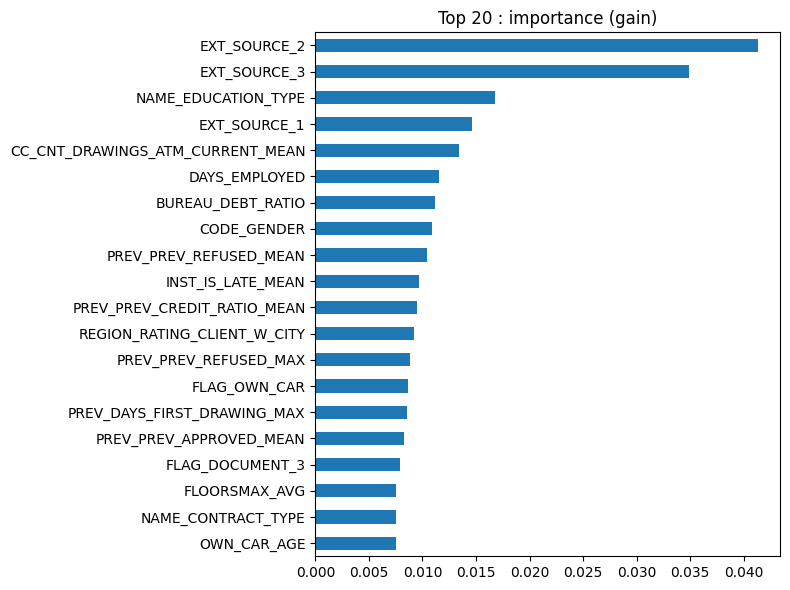

In [120]:
fig, ax = plt.subplots(figsize=(8, 6))
imp.head(20)[::-1].plot.barh(ax=ax)
ax.set_title("Top 20 : importance (gain)")
plt.tight_layout()
plt.show()

In [121]:
def source(col):
    for p in ["BUREAU_", "BB_", "PREV_", "POS_", "INST_", "CC_"]:
        if col.startswith(p):
            return p.strip("_")
    return "APP"

by_source = imp.groupby(imp.index.map(source)).agg(["sum", "count"])
by_source["part_des_colonnes"] = by_source["count"] / by_source["count"].sum()
by_source.sort_values("sum", ascending=False).round(3)

,sum,count,part_des_colonnes
APP,0.467,99,0.430
PREV,0.175,43,0.187
CC,0.150,39,0.170
INST,0.083,19,0.083
BUREAU,0.061,14,0.061
POS,0.048,11,0.048
BB,0.017,5,0.022


In [122]:
import optuna
optuna.logging.set_verbosity(optuna.logging.INFO)

In [ ]:
# optimisation bayesienne, randomsearch, gridsearch
def objective(trial):
    params = dict(
        max_depth=trial.suggest_int("max_depth", 3, 8),
        min_child_weight=trial.suggest_float("min_child_weight", 10, 200, log=True),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 0.8),
        reg_lambda=trial.suggest_float("reg_lambda", 1, 50, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
    )
    m = XGBClassifier(
        n_estimators=1000, learning_rate=0.05,
        tree_method="hist", enable_categorical=True,
        eval_metric="auc", early_stopping_rounds=100,
        n_jobs=-1, random_state=SEED, **params,
    )
    m.fit(data_fit, target_fit, eval_set=[(data_val, target_val)], verbose=False)
    trial.set_user_attr("best_iter", m.best_iteration)
    return m.best_score

In [124]:
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
)
study.optimize(objective, n_trials=15, timeout=45 * 60)
print("Meilleur AUC de validation :", round(study.best_value, 5))
print("Meilleurs paramètres :", study.best_params)
print("Arbres retenus :", study.best_trial.user_attrs["best_iter"])
study.trials_dataframe()[["number", "value", "params_max_depth", "params_min_child_weight"]].sort_values("value", ascending=False).head(8)

[I 2026-11-13 10:38:27,203] A new study created in memory with name: no-name-f781b446-699e-4c0c-9cf9-4aaff23acf71
[I 2026-11-13 10:40:00,619] Trial 0 finished with value: 0.7835630149780296 and parameters: {'max_depth': 5, 'min_child_weight': 172.54716573280342, 'subsample': 0.8927975767245621, 'colsample_bytree': 0.5993292420985183, 'reg_lambda': 1.841072920573868, 'reg_alpha': 0.004207053950287938}. Best is trial 0 with value: 0.7835630149780296.
[I 2026-11-13 10:41:56,330] Trial 1 finished with value: 0.7831742428108394 and parameters: {'max_depth': 3, 'min_child_weight': 133.94334706750476, 'subsample': 0.8404460046972835, 'colsample_bytree': 0.6540362888980227, 'reg_lambda': 1.0838581269344745, 'reg_alpha': 7.5794799533480015}. Best is trial 0 with value: 0.7835630149780296.
[I 2026-11-13 10:43:00,823] Trial 2 finished with value: 0.7811754523704272 and parameters: {'max_depth': 7, 'min_child_weight': 18.891200276189394, 'subsample': 0.6727299868828402, 'colsample_bytree': 0.39170

Meilleur AUC de validation : 0.78464
Meilleurs paramètres : {'max_depth': 6, 'min_child_weight': 17.39807471129172, 'subsample': 0.9878338511058234, 'colsample_bytree': 0.6875664116805573, 'reg_lambda': 39.46212980759094, 'reg_alpha': 3.795853142670642}
Arbres retenus : 743


,number,value,params_max_depth,params_min_child_weight
8,8,0.784636,6,17.398075
13,13,0.783765,6,15.885344
3,3,0.783570,5,23.927529
0,0,0.783563,5,172.547166
1,1,0.783174,3,133.943347
14,14,0.783031,5,12.696626
10,10,0.782775,7,71.042124
4,4,0.782687,5,105.084213


In [125]:
best = study.best_params
final_model = XGBClassifier(
    n_estimators=3000, learning_rate=0.05,
    tree_method="hist", enable_categorical=True,
    eval_metric="auc", early_stopping_rounds=100,
    n_jobs=-1, random_state=SEED, **best,
)
final_model.fit(data_fit, target_fit, eval_set=[(data_val, target_val)], verbose=200)
print("Arbres retenus :", final_model.best_iteration)
for name, X_, y_ in [("train", data_fit, target_fit), ("val", data_val, target_val), ("test", data_test, target_test)]:
    p = final_model.predict_proba(X_)[:, 1]
    print(f"{name:5s}  ROC-AUC = {roc_auc_score(y_, p):.4f}")

[0]	validation_0-auc:0.69442
[200]	validation_0-auc:0.77857
[400]	validation_0-auc:0.78263
[600]	validation_0-auc:0.78430
[800]	validation_0-auc:0.78442
[843]	validation_0-auc:0.78440
Arbres retenus : 743
train  ROC-AUC = 0.8817
val    ROC-AUC = 0.7851
test   ROC-AUC = 0.7863


In [126]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

In [127]:
# calibration
best_model = final_model
p_val = best_model.predict_proba(data_val)[:, 1]
p_test = best_model.predict_proba(data_test)[:, 1]
base = target_train.mean() * (1 - target_train.mean())
print(f"Brier test : {brier_score_loss(target_test, p_test):.4f}  (référence sans modèle : {base:.4f})")
frac_pos, mean_pred = calibration_curve(target_test, p_test, n_bins=10, strategy="quantile")

Brier test : 0.0657  (référence sans modèle : 0.0742)


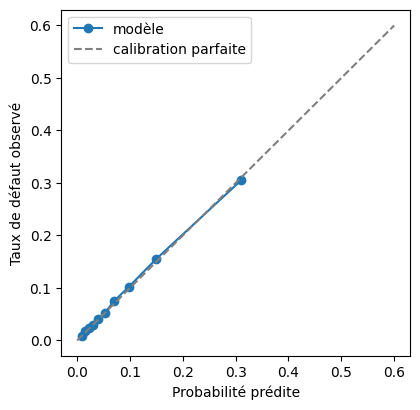

In [128]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(mean_pred, frac_pos, "o-", label="modèle")
ax.plot([0, 0.6], [0, 0.6], "--", color="gray", label="calibration parfaite")
ax.set_xlabel("Probabilité prédite")
ax.set_ylabel("Taux de défaut observé")
ax.legend()
plt.show()

In [129]:
# Seuil
C_FN, C_FP = 10, 1  # cout faux-neg, faux-pos
yv = np.asarray(target_val)
yt = np.asarray(target_test)

def total_cost(y, p, t, c_fn=C_FN, c_fp=C_FP):
    pred = p >= t
    fn = ((~pred) & (y == 1)).sum() #client accepté qui sont des défauts
    fp = (pred & (y == 0)).sum()  # client refuse qui n'auraient pas de défauts
    return c_fn * fn + c_fp * fp

grid = np.linspace(0.01, 0.60, 120)
costs = np.array([total_cost(yv, p_val, t) for t in grid])
t_star = grid[costs.argmin()]
print(f"Seuil optimal (validation) : {t_star:.3f}   |   seuil théorique : {C_FP / (C_FP + C_FN):.3f}")

Seuil optimal (validation) : 0.079   |   seuil théorique : 0.091


In [130]:
n = len(yt)
cost_model = total_cost(yt, p_test, t_star) / n
cost_accept_all = C_FN * yt.sum() / n
cost_refuse_all = C_FP * (yt == 0).sum() / n
print(f"Coût par client, test :  modèle {cost_model:.3f}  |  tout accepter {cost_accept_all:.3f}  |  tout refuser {cost_refuse_all:.3f}")

Coût par client, test :  modèle 0.489  |  tout accepter 0.807  |  tout refuser 0.919


In [131]:
from sklearn.metrics import confusion_matrix
pred = p_test >= t_star
tn, fp, fn, tp = confusion_matrix(yt, pred).ravel()
print(f"Taux de refus : {pred.mean():.1%} | Défauts détectés (recall) : {tp / (tp + fn):.1%} | Précision : {tp / (tp + fp):.1%}")

Taux de refus : 30.7% | Défauts détectés (recall) : 70.4% | Précision : 18.5%


In [132]:
rows = []
for ratio in [3, 5, 10, 20]:
    c = np.array([total_cost(yv, p_val, t, c_fn=ratio, c_fp=1) for t in grid])
    t_r = grid[c.argmin()]
    rows.append({"ratio FN/FP": ratio, "seuil": round(t_r, 3),
                 "taux de refus": (p_test >= t_r).mean(),
                 "coût/client (test)": total_cost(yt, p_test, t_r, c_fn=ratio, c_fp=1) / n})
pd.DataFrame(rows).round(3)

,ratio FN/FP,seuil,taux de refus,coût/client (test)
0,3,0.258,0.058,0.214
1,5,0.174,0.117,0.319
2,10,0.079,0.307,0.489
3,20,0.045,0.503,0.669


In [133]:
import shap

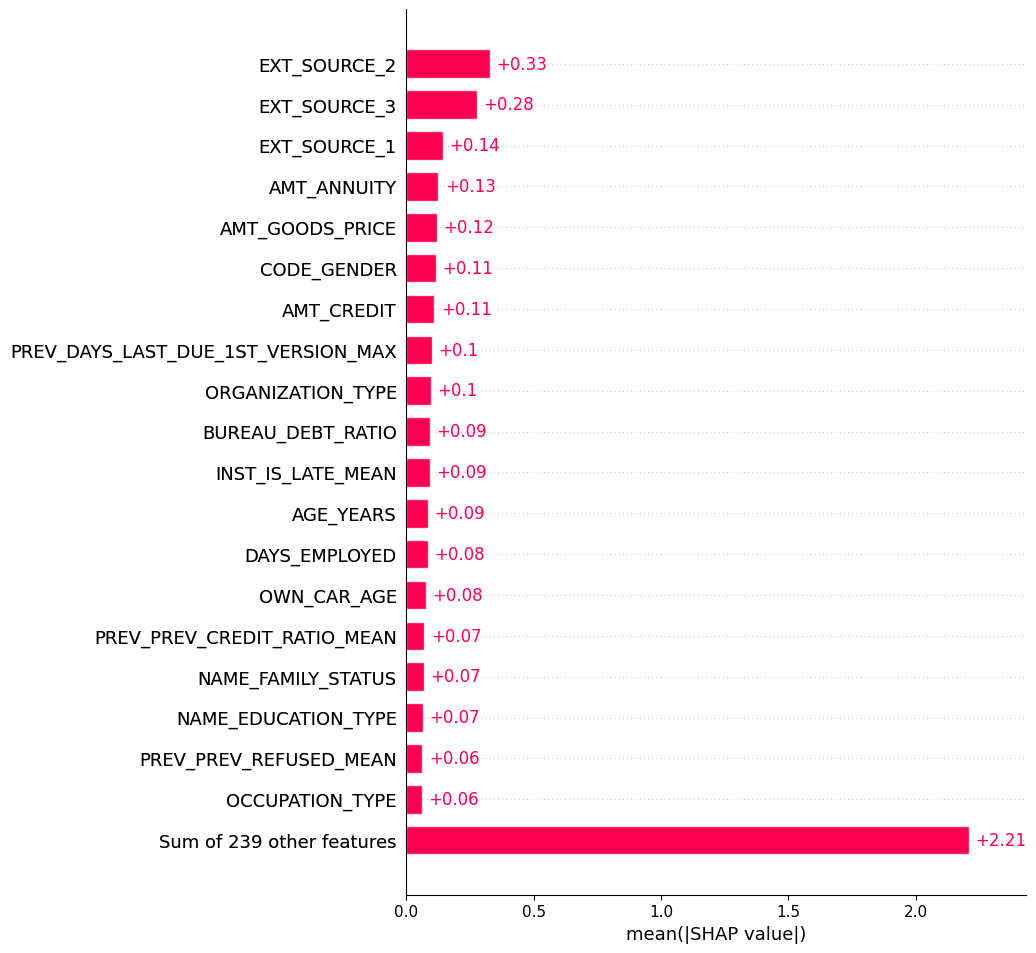

In [134]:
rng = np.random.RandomState(SEED)
idx = rng.choice(len(data_test), 5000, replace=False)
Xs = data_test.iloc[idx]
explainer = shap.TreeExplainer(best_model)
sv = explainer(Xs)
shap.plots.bar(sv, max_display=20)

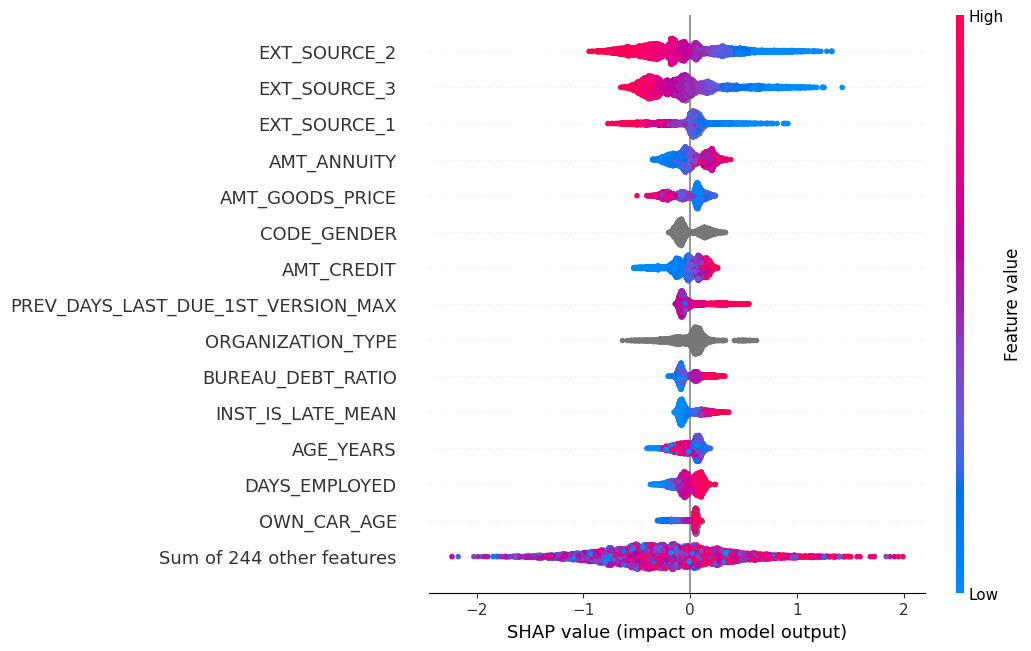

In [135]:
shap.plots.beeswarm(sv, max_display=15)

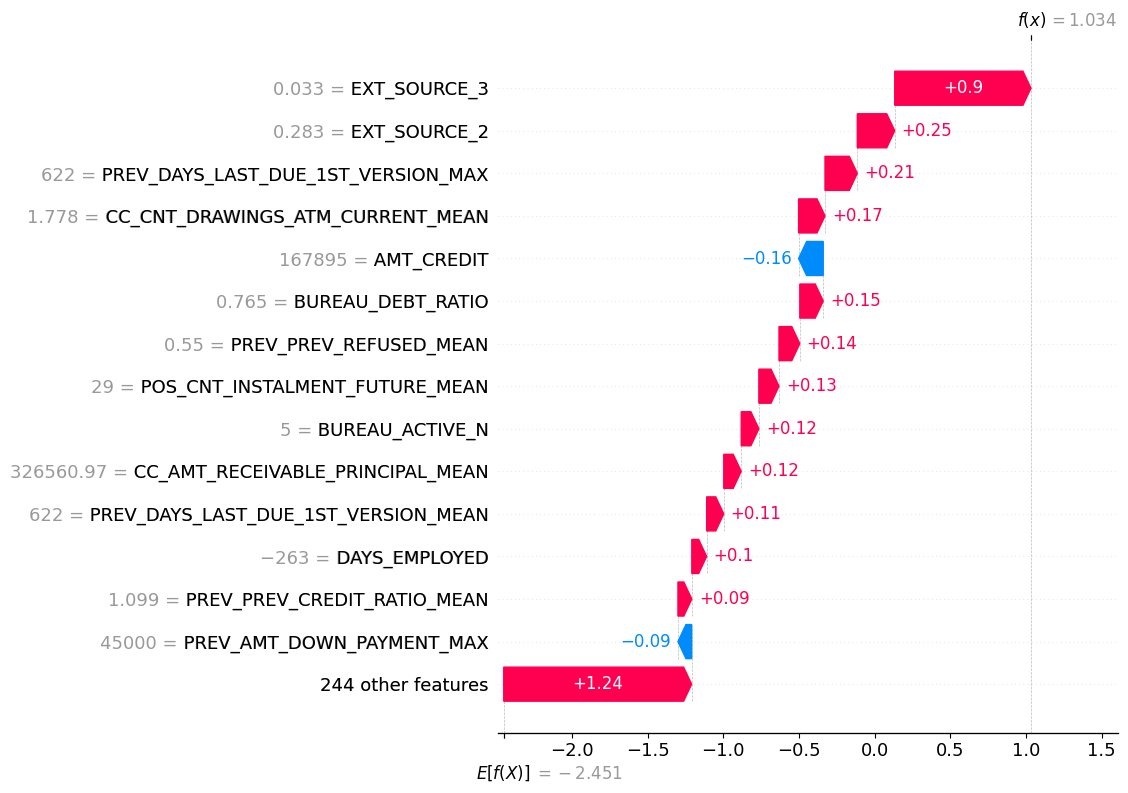

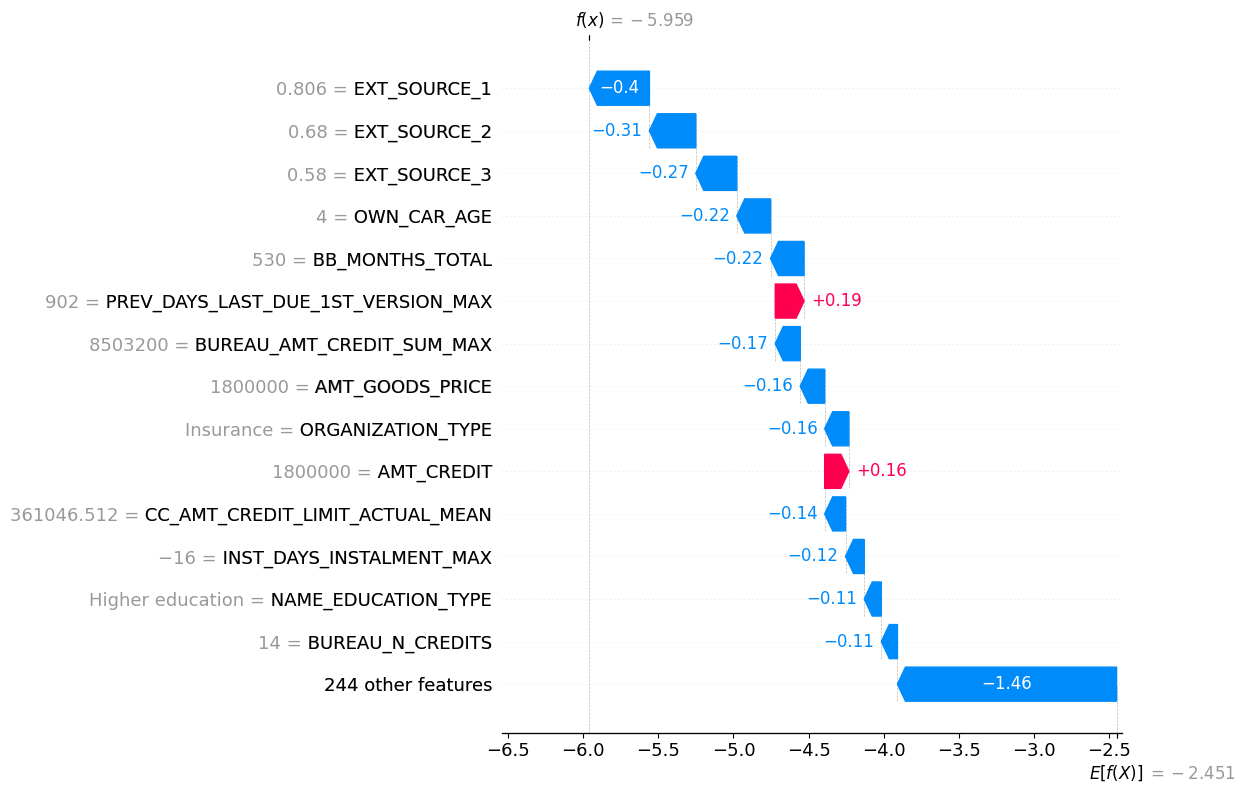

In [136]:
p_s = p_test[idx]
i_high, i_low = int(p_s.argmax()), int(p_s.argmin())
shap.plots.waterfall(sv[i_high], max_display=15)
shap.plots.waterfall(sv[i_low], max_display=15)

In [137]:
#sauvegarde pour le deploiement
import joblib

best_model.save_model("model.json")
joblib.dump({
    "features": list(data_train.columns),
    "cat_cols": cat_cols,
    "categories": {c: list(data_train[c].cat.categories) for c in cat_cols},
    "threshold": float(t_star),
    "costs": {"FN": C_FN, "FP": C_FP},
}, "model_meta.joblib")

['model_meta.joblib']

In [148]:
#Selection des variables importantes selon le sharp
FORM_FEATURES = [
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
      "AMT_ANNUITY", "AMT_GOODS_PRICE", "AMT_CREDIT", 
      "ORGANIZATION_TYPE", "PREV_DAYS_LAST_DUE_1ST_VERSION_MAX", 
      "BUREAU_DEBT_RATIO", "DAYS_EMPLOYED", "INST_IS_LATE_MEAN", "AGE_YEARS", "OWN_CAR_AGE",
        "PREV_PREV_CREDIT_RATIO_MEAN", "NAME_FAMILY_STATUS", "NAME_EDUCATION_TYPE",
]

# Ajout 
keep = FORM_FEATURES + ["HAS_BUREAU", "HAS_BB_STATUS", "BUREAU_N_CREDITS"]
Xp = data_test.copy()
hide = [c for c in Xp.columns if c not in keep]

for c in hide:
    if c in cat_cols:
        Xp[c] = pd.Categorical([np.nan] * len(Xp), categories=data_test[c].cat.categories)
    else:
        Xp[c] = np.nan

Xp[["HAS_BUREAU", "HAS_BB_STATUS", "BUREAU_N_CREDITS"]] = 0

p_partial = best_model.predict_proba(Xp)[:, 1]
print(f"AUC test, modèle complet   : {roc_auc_score(target_test, p_test):.4f}")
print(f"AUC test, formulaire partiel : {roc_auc_score(target_test, p_partial):.4f}")
print(f"Probabilité moyenne : complet {p_test.mean():.3f} | partiel {p_partial.mean():.3f}")

AUC test, modèle complet   : 0.7863
AUC test, formulaire partiel : 0.7456
Probabilité moyenne : complet 0.079 | partiel 0.153


In [1]:
%pip install streamlit

  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 13.6 MB/s eta 0:00:000:00:010:00:0101
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 27.8 MB/s eta 0:00:001m34.1 MB/s eta 0:00:01
Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl (18 kB)

[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
